# Titanic Survival Prediction using Machine Learning

This notebook inspects the supplied passenger data, builds leakage-safe classification pipelines, compares three models, and generates a CSV, plots, and PDF report from this run. The source CSV is read-only. Run every cell from top to bottom from the project folder.

**Target:** `Survived` (0 = did not survive, 1 = survived).

## 1. Imports and paths

All plots and generated reports are written beneath this project folder. A fixed seed makes the train/test split and randomized models reproducible.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from IPython.display import display

RANDOM_STATE = 42
PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "titanic.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Expected dataset at {DATA_PATH}. Run this notebook from the project folder.")
print(f"Project folder: {PROJECT_DIR}")
print(f"Dataset: {DATA_PATH}")
print(f"Plot output folder: {OUTPUT_DIR}")

Project folder: C:\Users\Dhivya sinnakkalai\Downloads\Titanic_ML_Project
Dataset: C:\Users\Dhivya sinnakkalai\Downloads\Titanic_ML_Project\titanic.csv
Plot output folder: C:\Users\Dhivya sinnakkalai\Downloads\Titanic_ML_Project\outputs


## 2. Load and inspect the dataset

Start by checking the shape, column names, sample rows, data types, and descriptive statistics. These observations are based on the actual CSV read at runtime.

In [2]:
raw_df = pd.read_csv(DATA_PATH)
print("Shape:", raw_df.shape)
print("Columns:", raw_df.columns.tolist())
display(raw_df.head())
print("\nData types and non-null counts:")
raw_df.info()
print("\nDescriptive statistics:")
display(raw_df.describe(include="all").T)

Shape: (891, 12)
Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Passenger, Mark 1",male,NaN,0,0,PC 10001,14.420294,NaN,S
1,2,0,3,"Passenger, Mark 2",male,14.0,1,0,PC 10002,137.372194,C123,Q
2,3,1,2,"Passenger, Mark 3",female,22.0,0,0,PC 10003,234.503052,C123,S
3,4,1,3,"Passenger, Mark 4",female,38.0,0,0,PC 10004,357.217504,C123,S
4,5,0,1,"Passenger, Mark 5",male,NaN,1,0,PC 10005,377.547312,NaN,S



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        227 non-null    object 
 11  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.324355,0.468396,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.845426,1.0,1.5,3.0,3.0,3.0
Name,891,891,"Passenger, Mark 1",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,26.861345,15.317366,2.0,22.0,27.0,35.0,54.0
SibSp,891.0,NaN,NaN,NaN,0.406285,0.77816,0.0,0.0,0.0,1.0,3.0
Parch,891.0,NaN,NaN,NaN,0.308642,0.651811,0.0,0.0,0.0,0.0,2.0
Ticket,891,891,PC 10001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,256.69479,146.128716,9.229054,128.618058,255.708087,380.247382,512.047606


## 3. Clean headers and check data quality

Headers are normalized to lowercase snake case. We verify the target, duplicates, missingness, target labels, and reasonable domain constraints. A failed target check stops the analysis rather than silently training on unsuitable data.

In [3]:
df = raw_df.copy()
df.columns = (df.columns.astype(str).str.strip()
              .str.replace(r"\s+", "_", regex=True).str.lower())
if "survived" not in df.columns:
    raise ValueError("Required target column 'Survived' was not found in the dataset.")

duplicate_count = int(df.duplicated().sum())
missing_summary = df.isna().sum().sort_values(ascending=False)
target_values = set(df["survived"].dropna().unique())
invalid_target_count = int((~df["survived"].isin([0, 1])).sum())
invalid_checks = {}
for column in ["age", "fare", "sibsp", "parch"]:
    if column in df.columns:
        invalid_checks[f"negative_{column}"] = int((df[column] < 0).sum())
if "pclass" in df.columns:
    invalid_checks["invalid_pclass"] = int((~df["pclass"].isin([1, 2, 3])).sum())

print(f"Exact duplicate rows: {duplicate_count}")
print("Missing values by column:")
display(missing_summary.to_frame("missing_count").query("missing_count > 0"))
print("Target values:", sorted(target_values))
print("Invalid/missing target rows:", invalid_target_count)
print("Domain checks:", invalid_checks)
if invalid_target_count:
    raise ValueError("Survived must contain only non-missing 0/1 labels.")
if duplicate_count:
    print("Duplicate rows are reported but retained to avoid removing observations without provenance.")
display(df["survived"].value_counts().rename(index={0: "Did not survive", 1: "Survived"}).to_frame("passengers"))

Exact duplicate rows: 0
Missing values by column:


,missing_count
cabin,664
age,177


Target values: [np.int64(0), np.int64(1)]
Invalid/missing target rows: 0
Domain checks: {'negative_age': 0, 'negative_fare': 0, 'negative_sibsp': 0, 'negative_parch': 0, 'invalid_pclass': 0}


,passengers
survived,
Did not survive,602
Survived,289


## 4. Exploratory data analysis

The target is checked for imbalance, missingness is visualized, and numeric distributions and boxplots are saved. Boxplot flags are screening signals only; valid passenger observations are not deleted just for falling outside an IQR fence.

Target counts: {0: 602, 1: 289}
Target proportions: {0: 0.676, 1: 0.324}
The classes are moderately imbalanced; stratification preserves their proportions in the split.


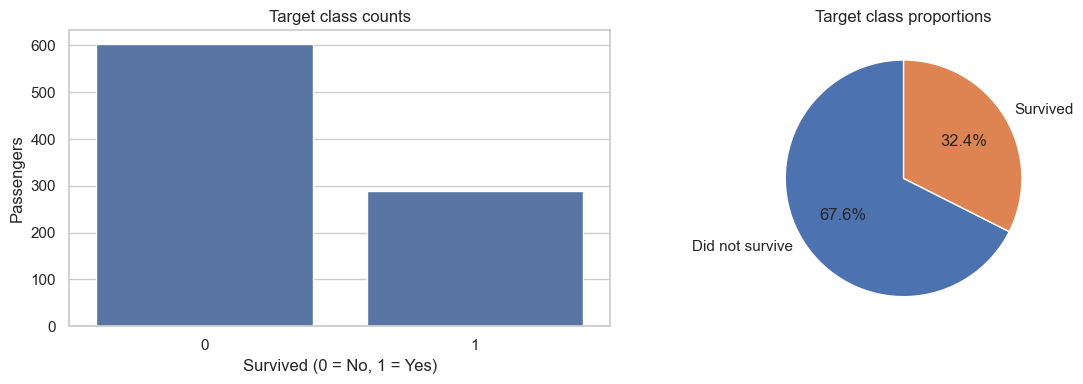

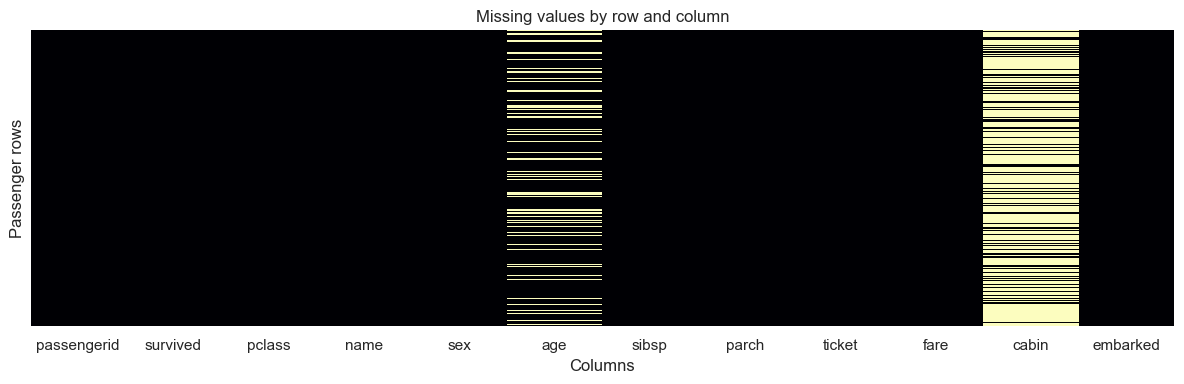

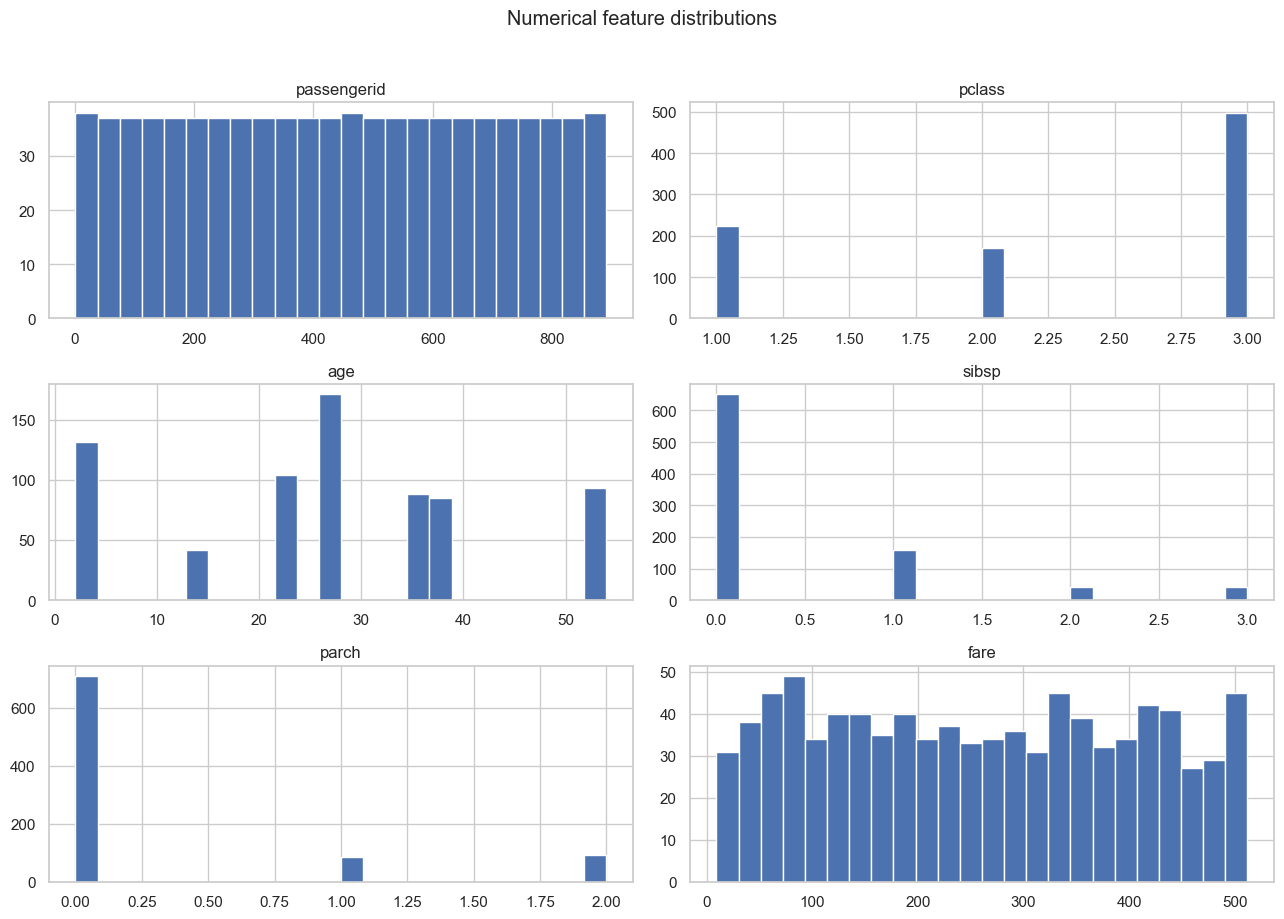

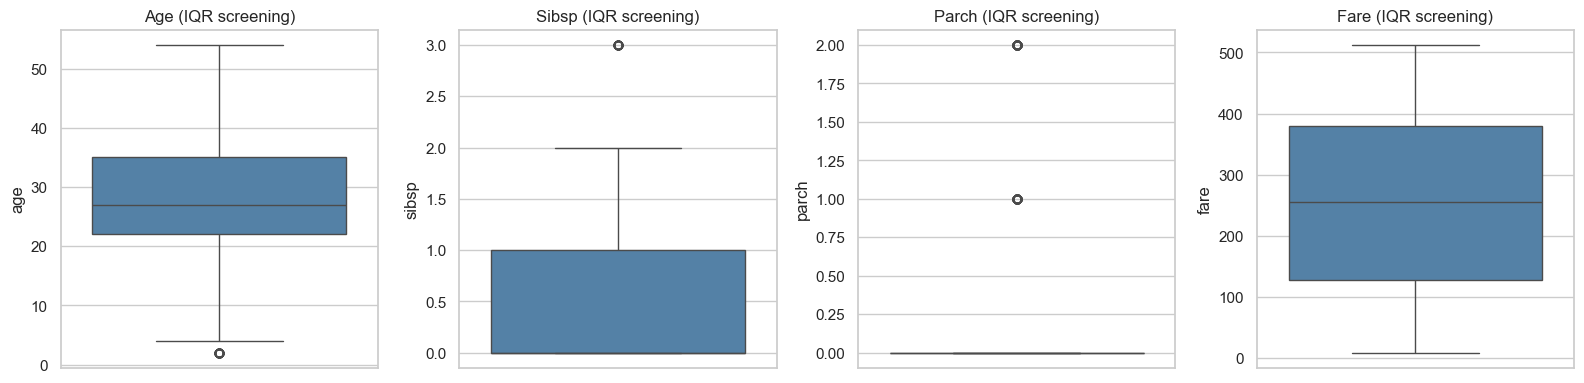

In [4]:
target_counts = df["survived"].value_counts().sort_index()
target_share = df["survived"].value_counts(normalize=True).sort_index()
print("Target counts:", target_counts.to_dict())
print("Target proportions:", target_share.round(3).to_dict())
print("The classes are moderately imbalanced; stratification preserves their proportions in the split.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="survived", ax=axes[0])
axes[0].set(title="Target class counts", xlabel="Survived (0 = No, 1 = Yes)", ylabel="Passengers")
axes[1].pie(target_counts.values, labels=["Did not survive", "Survived"], autopct="%1.1f%%", startangle=90)
axes[1].set_title("Target class proportions")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "target_distribution.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="magma", ax=ax)
ax.set(title="Missing values by row and column", xlabel="Columns", ylabel="Passenger rows")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "missing_values.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

numeric_columns_all = df.select_dtypes(include=np.number).columns.drop("survived", errors="ignore").tolist()
if numeric_columns_all:
    df[numeric_columns_all].hist(figsize=(13, 9), bins=24, edgecolor="white")
    plt.suptitle("Numerical feature distributions", y=1.02)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "numeric_distributions.png", dpi=160, bbox_inches="tight")
    display(plt.gcf())
    plt.close()

box_columns = [column for column in ["age", "sibsp", "parch", "fare"] if column in df.columns]
if box_columns:
    fig, axes = plt.subplots(1, len(box_columns), figsize=(4 * len(box_columns), 4))
    axes = np.atleast_1d(axes)
    for ax, column in zip(axes, box_columns):
        sns.boxplot(y=df[column], ax=ax, color="steelblue")
        ax.set_title(f"{column.title()} (IQR screening)")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "outlier_boxplots.png", dpi=160, bbox_inches="tight")
    display(fig)
    plt.close(fig)

## 5. Feature engineering and stratified split

`FamilySize` and `IsAlone` are created only when their source columns exist. Passenger ID, name, ticket, and cabin are excluded: IDs and near-unique text can memorize records, while cabin is mostly missing. The split happens before learned preprocessing; imputation, encoding, scaling, and feature filtering are all fitted within model pipelines.

In [5]:
model_df = df.copy()
if {"sibsp", "parch"}.issubset(model_df.columns):
    model_df["family_size"] = model_df["sibsp"] + model_df["parch"] + 1
    model_df["is_alone"] = (model_df["family_size"] == 1).astype(int)
else:
    print("SibSp/Parch not both present; family features are omitted.")

candidate_features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked", "family_size", "is_alone"]
feature_columns = [column for column in candidate_features if column in model_df.columns]
if not feature_columns:
    raise ValueError("No supported passenger predictor columns are available.")
X = model_df[feature_columns].copy()
y = model_df["survived"].astype(int).copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Predictors:", feature_columns)
print(f"Training rows: {len(X_train)}; test rows: {len(X_test)}")
print("Training target proportions:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print("Test target proportions:", y_test.value_counts(normalize=True).sort_index().round(3).to_dict())
print("PassengerId, Name, Ticket, and Cabin are not predictors.")

Predictors: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'family_size', 'is_alone']
Training rows: 712; test rows: 179
Training target proportions: {0: 0.676, 1: 0.324}
Test target proportions: {0: 0.676, 1: 0.324}
PassengerId, Name, Ticket, and Cabin are not predictors.


## 6. Training-only diagnostics and preprocessing plan

IQR cutoffs and correlation checks below use training predictors only. Potential outliers are retained: small counts such as one or two family members are meaningful, and there is no evidence that these rows are data-entry errors. Fare's skew is checked before deciding about a log transform. A `ColumnTransformer` will impute missing values, scale numeric values for Logistic Regression, one-hot encode categoricals, and filter zero-variance encoded columns, all inside cross-validation folds.

Training-only IQR outlier diagnostics (no rows removed):


,feature,lower_fence,upper_fence,training_values_flagged
0,pclass,0.50000,4.500000,0
1,age,2.50000,54.500000,39
2,sibsp,-1.50000,2.500000,36
3,parch,0.00000,0.000000,146
4,fare,-241.35274,754.500923,0
5,family_size,-0.50000,3.500000,58
6,is_alone,-1.50000,2.500000,0


Training Fare skewness: 0.039.
Fare is not strongly skewed in this dataset; no log transform is applied.
Constant numeric predictors in training data: None
Training numeric feature pairs with |correlation| >= 0.85: None


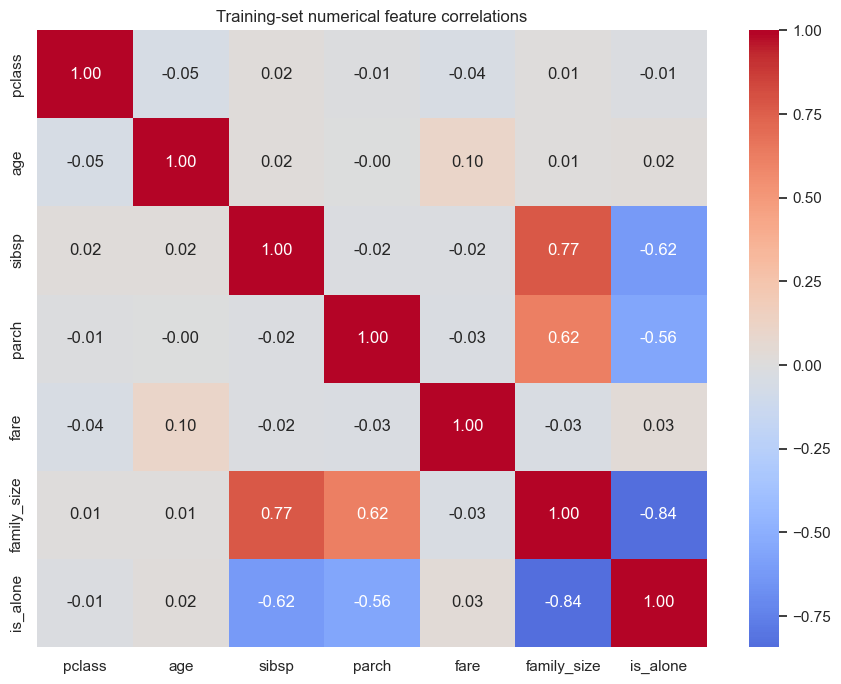

No manual correlation-based deletion is applied: the feature set is small, and the pipeline's zero-variance filter is fitted on training folds.


In [6]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
iqr_rows = []
for column in numeric_features:
    values = X_train[column].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = int(((values < lower) | (values > upper)).sum())
    iqr_rows.append({"feature": column, "lower_fence": lower, "upper_fence": upper,
                     "training_values_flagged": flagged})
iqr_diagnostics = pd.DataFrame(iqr_rows)
print("Training-only IQR outlier diagnostics (no rows removed):")
display(iqr_diagnostics)

if "fare" in X_train.columns:
    fare_skew = float(X_train["fare"].dropna().skew())
    print(f"Training Fare skewness: {fare_skew:.3f}.")
    if abs(fare_skew) < 1:
        print("Fare is not strongly skewed in this dataset; no log transform is applied.")
    else:
        print("Fare is skewed; for this baseline comparison we retain original units and scaling, and report the skew.")

numeric_train = X_train[numeric_features].copy()
constant_features = [column for column in numeric_features if numeric_train[column].nunique(dropna=True) <= 1]
print("Constant numeric predictors in training data:", constant_features or "None")
corr_features = [column for column in numeric_features if numeric_train[column].nunique(dropna=True) > 1]
if len(corr_features) >= 2:
    train_corr = numeric_train[corr_features].corr()
    upper_triangle = train_corr.where(np.triu(np.ones(train_corr.shape), k=1).astype(bool))
    high_corr_pairs = [(a, b, float(upper_triangle.loc[a, b]))
                       for a in upper_triangle.index for b in upper_triangle.columns
                       if pd.notna(upper_triangle.loc[a, b]) and abs(upper_triangle.loc[a, b]) >= 0.85]
    print("Training numeric feature pairs with |correlation| >= 0.85:", high_corr_pairs or "None")
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(train_corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=ax)
    ax.set_title("Training-set numerical feature correlations")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=160, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print("No manual correlation-based deletion is applied: the feature set is small, and the pipeline's zero-variance filter is fitted on training folds.")
else:
    train_corr = pd.DataFrame()
    print("Too few varying numeric features for a correlation heatmap.")

## 7. Train and compare three classifiers

Five-fold stratified cross-validation is performed on training data only. Class weighting is used for Logistic Regression and Random Forest to reduce bias toward the more common class; Gradient Boosting is included as an unweighted baseline. Scaling is useful for Logistic Regression and harmless within the shared pipeline. `VarianceThreshold` is learned separately in every fold, avoiding preprocessing leakage.

In [7]:
transformers = []
if numeric_features:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    transformers.append(("numeric", numeric_pipeline, numeric_features))
if categorical_features:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop", verbose_feature_names_out=True)
model_definitions = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.05,
                                                     max_depth=2, random_state=RANDOM_STATE),
}
pipelines = {
    name: Pipeline([
        ("preprocess", preprocessor),
        ("remove_constant", VarianceThreshold(threshold=0.0)),
        ("model", estimator),
    ])
    for name, estimator in model_definitions.items()
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}
results = []
fitted_models = {}
for name, pipeline in pipelines.items():
    cv_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring,
                               n_jobs=1, error_score="raise")
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    results.append({
        "model": name,
        "cv_accuracy_mean": cv_scores["test_accuracy"].mean(),
        "cv_precision_mean": cv_scores["test_precision"].mean(),
        "cv_recall_mean": cv_scores["test_recall"].mean(),
        "cv_f1_mean": cv_scores["test_f1"].mean(),
        "cv_f1_std": cv_scores["test_f1"].std(ddof=1),
        "cv_roc_auc_mean": cv_scores["test_roc_auc"].mean(),
        "test_accuracy": accuracy_score(y_test, predictions),
        "test_precision": precision_score(y_test, predictions, zero_division=0),
        "test_recall": recall_score(y_test, predictions, zero_division=0),
        "test_f1": f1_score(y_test, predictions, zero_division=0),
        "test_roc_auc": roc_auc_score(y_test, probabilities),
    })
    print(f"Completed {name}")

comparison = pd.DataFrame(results).sort_values(
    ["cv_f1_mean", "cv_roc_auc_mean"], ascending=False
).reset_index(drop=True)
comparison.to_csv(PROJECT_DIR / "model_comparison.csv", index=False, float_format="%.6f")
best_model_name = comparison.loc[0, "model"]
print("Selected by mean stratified CV F1 (CV ROC-AUC breaks ties):", best_model_name)
display(comparison.round(4))
print("The held-out test metrics below are a final estimate and are not used for model selection.")

Completed Logistic Regression


Completed Random Forest


Completed Gradient Boosting
Selected by mean stratified CV F1 (CV ROC-AUC breaks ties): Logistic Regression


,model,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,Logistic Regression,0.7387,0.5803,0.7182,0.6399,0.0534,0.8000,0.6816,0.5072,0.6034,0.5512,0.7325
1,Random Forest,0.7275,0.5772,0.6097,0.5891,0.0606,0.7752,0.7374,0.6000,0.5690,0.5841,0.7086
2,Gradient Boosting,0.7486,0.6479,0.5364,0.5825,0.0743,0.8038,0.7486,0.6327,0.5345,0.5794,0.7434


The held-out test metrics below are a final estimate and are not used for model selection.


## 8. Held-out evaluation and model plots

Accuracy is shown alongside precision, recall, F1, and ROC-AUC. Confusion matrices use the untouched test labels. Random Forest feature importance is descriptive of this fitted model, not a causal explanation.

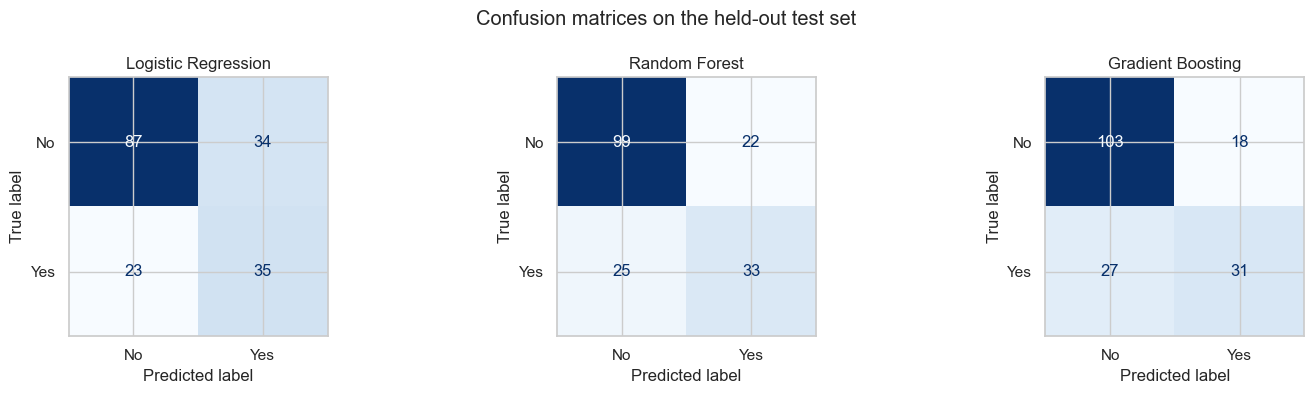

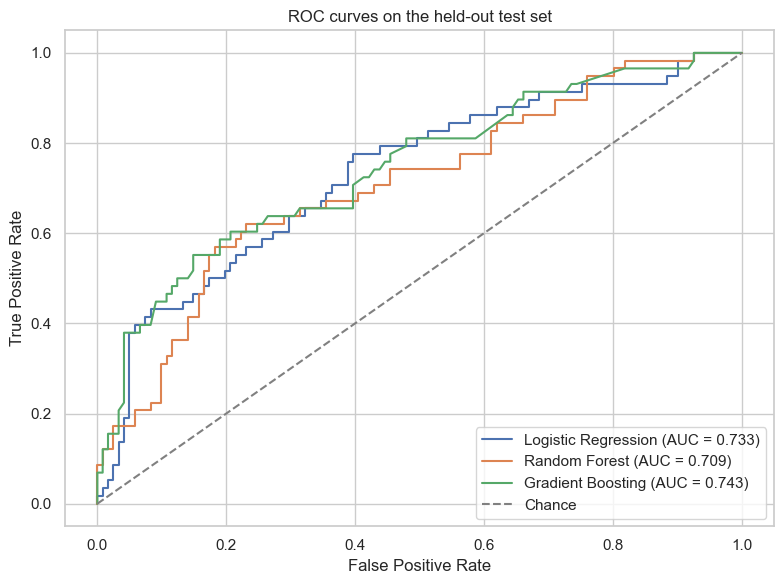

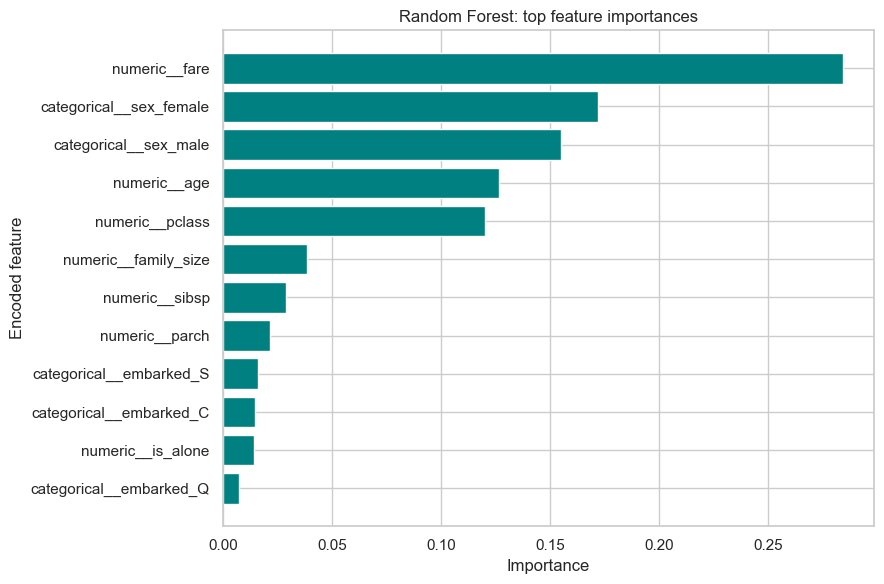

,feature,importance
0,numeric__fare,0.284430
1,categorical__sex_female,0.172187
2,categorical__sex_male,0.155220
3,numeric__age,0.126613
4,numeric__pclass,0.120020
5,numeric__family_size,0.038609
6,numeric__sibsp,0.028727
7,numeric__parch,0.021604
8,categorical__embarked_S,0.016021
9,categorical__embarked_C,0.014835


In [8]:
fig, axes = plt.subplots(1, len(fitted_models), figsize=(15, 4))
for ax, (name, pipeline) in zip(axes, fitted_models.items()):
    predictions = pipeline.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=["No", "Yes"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
fig.suptitle("Confusion matrices on the held-out test set")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 6))
for name, pipeline in fitted_models.items():
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    curve_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {curve_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set(title="ROC curves on the held-out test set", xlabel="False Positive Rate", ylabel="True Positive Rate")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "roc_curves.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

forest_pipeline = fitted_models["Random Forest"]
all_feature_names = forest_pipeline.named_steps["preprocess"].get_feature_names_out()
selected_mask = forest_pipeline.named_steps["remove_constant"].get_support()
selected_feature_names = all_feature_names[selected_mask]
importances = forest_pipeline.named_steps["model"].feature_importances_
importance_table = (pd.DataFrame({"feature": selected_feature_names, "importance": importances})
                    .sort_values("importance", ascending=False).head(15).sort_values("importance"))
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importance_table["feature"], importance_table["importance"], color="teal")
ax.set(title="Random Forest: top feature importances", xlabel="Importance", ylabel="Encoded feature")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "random_forest_feature_importance.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)
display(importance_table.sort_values("importance", ascending=False).reset_index(drop=True))

## 9. Generate the PDF report from this run

The PDF below uses the computed data checks, cross-validation/test metrics, selected model, and saved plots from this notebook execution. It contains no pre-filled performance scores.

In [9]:
def add_text_page(pdf, title, paragraphs):
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(0.08, 0.94, title, fontsize=19, fontweight="bold", va="top")
    body = "\n\n".join(f"- {paragraph}" for paragraph in paragraphs)
    fig.text(0.08, 0.87, body, fontsize=10, va="top", wrap=True, linespacing=1.6)
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

survival_rate = float(df["survived"].mean())
age_missing = int(df["age"].isna().sum()) if "age" in df.columns else 0
cabin_missing = int(df["cabin"].isna().sum()) if "cabin" in df.columns else 0
fare_range = (f"{df['fare'].min():.2f} to {df['fare'].max():.2f}" if "fare" in df.columns else "not available")
fare_skew_value = float(X_train["fare"].dropna().skew()) if "fare" in X_train.columns else float("nan")
best_row = comparison.iloc[0]
pdf_path = PROJECT_DIR / "summary_report.pdf"
with PdfPages(pdf_path) as pdf:
    add_text_page(pdf, "Titanic Survival Prediction", [
        "Problem: classify whether a passenger survived (1) or did not survive (0) using passenger attributes.",
        f"Dataset: {len(df)} rows and {df.shape[1]} columns; target survival rate {survival_rate:.1%}; exact duplicate rows {duplicate_count}.",
        f"Missingness: Age has {age_missing} missing values and Cabin has {cabin_missing}; observed Fare range is {fare_range}. The regular passenger name/ticket patterns and Fare range should be confirmed with the data source.",
        "Data preparation: normalize column names; engineer FamilySize and IsAlone when source columns exist; exclude PassengerId, Name, Ticket, and Cabin from predictors. Split 80/20 with stratification and fixed seed.",
        "Leakage control: median/mode imputation, scaling, one-hot encoding, and zero-variance filtering live inside sklearn pipelines and are refit within each training fold. Five-fold stratified CV is run on training data only.",
        f"Feature/outlier review: IQR and correlation diagnostics use training data; no valid-looking rows are discarded. Fare skewness was {fare_skew_value:.3f}, so no log transformation was justified. Constant transformed features are filtered in the training pipeline; correlated predictors are retained.",
    ])
    add_text_page(pdf, "Results, interpretation, and limitations", [
        "Models: Logistic Regression and Random Forest use balanced class weights; Gradient Boosting is an unweighted comparison. Selection uses mean CV F1, with mean CV ROC-AUC as a tie-break.",
        f"Selected model: {best_model_name}; CV F1 = {best_row['cv_f1_mean']:.3f}, CV ROC-AUC = {best_row['cv_roc_auc_mean']:.3f}. Held-out test F1 = {best_row['test_f1']:.3f} and ROC-AUC = {best_row['test_roc_auc']:.3f}.",
        "Interpretation and limitations: these results apply to this provided dataset and one reproducible split. The passenger names/ticket labels look artificially regular and should be validated against provenance; the recorded Fare range also warrants source confirmation. IQR flags are retained unless independently shown invalid. Scores are not causal or guaranteed to generalize.",
        "Future work: validate against authoritative data, tune hyperparameters within nested CV, evaluate calibration and threshold trade-offs, and test on an external holdout.",
    ])

    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.axis("off")
    report_columns = ["model", "cv_f1_mean", "cv_roc_auc_mean", "test_accuracy", "test_precision",
                      "test_recall", "test_f1", "test_roc_auc"]
    table_df = comparison[report_columns].copy().round(3)
    table = ax.table(cellText=table_df.values, colLabels=table_df.columns,
                     loc="center", cellLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.6)
    ax.set_title("Actual cross-validation and held-out test metrics", pad=18)
    fig.tight_layout()
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    report_plots = [
        ("Target distribution and missingness", ["target_distribution.png", "missing_values.png"]),
        ("Numerical distributions and IQR screening", ["numeric_distributions.png", "outlier_boxplots.png"]),
        ("Correlation and held-out ROC curves", ["correlation_heatmap.png", "roc_curves.png"]),
        ("Confusion matrices and Random Forest importance", ["confusion_matrices.png", "random_forest_feature_importance.png"]),
    ]
    for page_title, image_names in report_plots:
        existing_images = [OUTPUT_DIR / image_name for image_name in image_names
                           if (OUTPUT_DIR / image_name).is_file()]
        fig, axes = plt.subplots(1, len(existing_images), figsize=(12, 5.8))
        axes = np.atleast_1d(axes)
        for ax, image_path in zip(axes, existing_images):
            ax.imshow(plt.imread(image_path))
            ax.set_title(image_path.stem.replace("_", " ").title(), fontsize=9)
            ax.axis("off")
        fig.suptitle(page_title)
        fig.tight_layout()
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

print(f"Saved model comparison to {PROJECT_DIR / 'model_comparison.csv'}")
print(f"Saved PDF report to {pdf_path} ({pdf_path.stat().st_size:,} bytes)")
print("Generated plots:", sorted(path.name for path in OUTPUT_DIR.glob("*.png")))

Saved model comparison to C:\Users\Dhivya sinnakkalai\Downloads\Titanic_ML_Project\model_comparison.csv
Saved PDF report to C:\Users\Dhivya sinnakkalai\Downloads\Titanic_ML_Project\summary_report.pdf (255,081 bytes)
Generated plots: ['confusion_matrices.png', 'correlation_heatmap.png', 'missing_values.png', 'numeric_distributions.png', 'outlier_boxplots.png', 'random_forest_feature_importance.png', 'roc_curves.png', 'target_distribution.png']


## 10. Conclusions

The selected classifier and its cross-validation/test scores above are computed from the supplied dataset at execution time. Use the F1 and ROC-AUC values together with precision/recall and confusion matrices rather than relying on accuracy alone. The source file is unchanged; rerunning the notebook refreshes the generated outputs.